In [ ]:

!pip install numpy scipy matplotlib pydub librosa

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   -------------- ------------------------- 1.0/2.8 MB 5.3 MB/s eta 0:00:01
   ----------------------------- ---------- 2.1/2.8 MB 5.1 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 5.0 MB/s  0:00:00
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
    --------------------------------------- 1.0/43.0 MB 5.1 MB/s eta 0:00:09
   - -------------------------------------- 1.6/43.0 MB 4.6 MB/s eta 0:00:10
   -- ------------------------------------- 2.9/43.0 MB 4.7 MB/s eta 0:00:09
   --- ------------------------------------ 3.9/43.0 MB 4.9 MB/s eta 0:00:08
   ---- ----------------------------------- 5.0/43.0 MB 4.9 MB/s eta 0:00:08
   ----- ---------------------------------- 6.0/43.0 MB 4.9 MB/s eta 0:00:08
   ------ --------------------------------- 6.8/43.0 MB 4.9 MB/s eta 0:00:08
   ------- -------------------------------- 7.9/43.0 MB 4.9 MB/s eta 0:00:08
   -------- --------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:

pip install --upgrade pip

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 1.5 MB/s eta 0:00:01
   ----------------- ---------------------- 0.8/1.8 MB 1.5 MB/s eta 0:00:01
   ----------------------- ---------------- 1.0/1.8 MB 1.5 MB/s eta 0:00:01
   ---------------------------------- ----- 1.6/1.8 MB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 1.6 MB/s  0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 26.1.2
    Uninstalling pip-26.1.2:
      Successfully uninstalled pip-26.1.2
Note: you may need to restart the kernel to use updated packages.


In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

# 1. Đường dẫn file WAV đầu vào của bạn
AUDIO_PATH = r"C:\Users\DAT\Downloads\1789984511516_55412345060943655_4786764310726840205.wav"  # Thay tên file .wav của bạn vào đây

# Tạo thư mục lưu kết quả
os.makedirs("figures", exist_ok=True)
os.makedirs("audio", exist_ok=True)

# 2. Đọc file WAV
x_raw, Fs = sf.read(AUDIO_PATH)
info = sf.info(AUDIO_PATH)

channels = info.channels
duration_sec = info.duration
bit_depth_str = info.subtype  # Ví dụ: 'PCM_16', 'PCM_24', 'FLOAT'
file_size_bytes = os.path.getsize(AUDIO_PATH)

print("=" * 50)
print("--- THÔNG TIN METADATA CỦA FILE WAV ---")
print(f"Tệp âm thanh: {AUDIO_PATH}")
print(f"Tần số lấy mẫu (Fs): {Fs} Hz")
print(f"Số kênh: {channels} ({'Stereo' if channels == 2 else 'Mono'})")
print(f"Định dạng mẫu: {bit_depth_str}")
print(f"Thời lượng: {duration_sec:.3f} giây")
print(f"Kích thước file: {file_size_bytes / (1024*1024):.2f} MB")
print("=" * 50)

# 3. Chuyển đổi sang Mono (nếu là Stereo) và Chuẩn hóa về [-1, 1]
if channels > 1:
    x = np.mean(x_raw, axis=1)  # Lấy trung bình 2 kênh để thành Mono
else:
    x = x_raw.copy()

# Nếu tín hiệu chưa chuẩn hóa về [-1, 1] (ví dụ dạng int16), chuẩn hóa nó:
if np.max(np.abs(x)) > 1.0:
    x = x / np.max(np.abs(x))

N_total = len(x)
time_axis = np.arange(N_total) / Fs

print("Chuyển đổi Mono & Chuẩn hóa hoàn tất!")
print(f"Tổng số mẫu (N): {N_total}")

--- THÔNG TIN METADATA CỦA FILE WAV ---
Tệp âm thanh: C:\Users\DAT\Downloads\1789984511516_55412345060943655_4786764310726840205.wav
Tần số lấy mẫu (Fs): 44100 Hz
Số kênh: 2 (Stereo)
Định dạng mẫu: PCM_16
Thời lượng: 3.648 giây
Kích thước file: 0.61 MB
Chuyển đổi Mono & Chuẩn hóa hoàn tất!
Tổng số mẫu (N): 160892


--- THÔNG SỐ MIỀN THỜI GIAN ---
Peak (Biên độ đỉnh): 0.5901
RMS (Giá trị hiệu dụng): 0.0954 (-20.41 dBFS)
Tổng năng lượng (E): 1465.39
Tín hiệu an toàn, không bị Clipping.


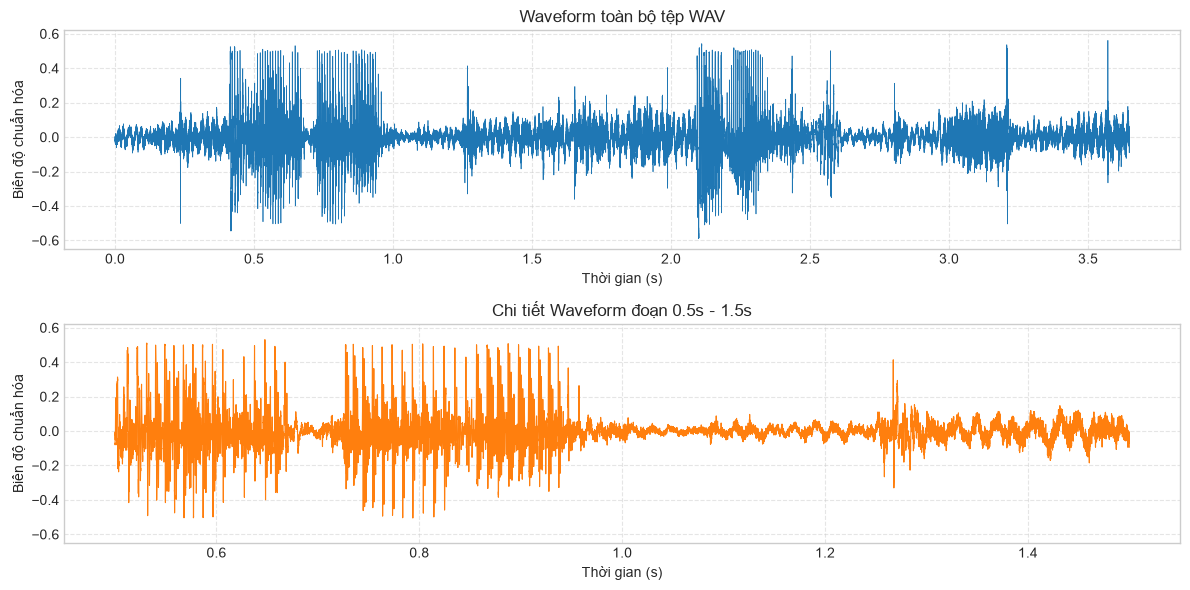

In [17]:
# 1. Tính toán các đại lượng miền thời gian
peak_val = np.max(np.abs(x))
rms_val = np.sqrt(np.mean(x ** 2))
energy_val = np.sum(x ** 2)
rms_dbfs = 20 * np.log10(rms_val + 1e-12)

print("--- THÔNG SỐ MIỀN THỜI GIAN ---")
print(f"Peak (Biên độ đỉnh): {peak_val:.4f}")
print(f"RMS (Giá trị hiệu dụng): {rms_val:.4f} ({rms_dbfs:.2f} dBFS)")
print(f"Tổng năng lượng (E): {energy_val:.2f}")

if peak_val >= 1.0:
    print("CẢNH BÁO: Tín hiệu có nguy cơ bị Clipping!")
else:
    print("Tín hiệu an toàn, không bị Clipping.")

# 2. Vẽ biểu đồ Waveform
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharey=True)

# Waveform toàn bộ tệp
axes[0].plot(time_axis, x, color='tab:blue', linewidth=0.5)
axes[0].set_title("Waveform toàn bộ tệp WAV")
axes[0].set_xlabel("Thời gian (s)")
axes[0].set_ylabel("Biên độ chuẩn hóa")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Trích xuất 1 đoạn ngắn (0.5s đến 1.5s hoặc phù hợp với độ dài file)
t_start = 0.5
t_end = min(1.5, duration_sec)
idx_start, idx_end = int(t_start * Fs), int(t_end * Fs)

axes[1].plot(time_axis[idx_start:idx_end], x[idx_start:idx_end], color='tab:orange', linewidth=0.8)
axes[1].set_title(f"Chi tiết Waveform đoạn {t_start}s - {t_end}s")
axes[1].set_xlabel("Thời gian (s)")
axes[1].set_ylabel("Biên độ chuẩn hóa")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("figures/waveform.png", dpi=300)
plt.show()

Frequency bin spacing (Δf): 0.673 Hz

--- CÁC ĐỈNH PHỔ NỔI BẬT (TOP PEAKS) ---
Peak 1: Tần số = 687.72 Hz | Biên độ = 0.00 dB
Peak 2: Tần số = 774.52 Hz | Biên độ = -3.60 dB
Peak 3: Tần số = 49.80 Hz | Biên độ = -3.75 dB
Peak 4: Tần số = 609.66 Hz | Biên độ = -3.99 dB
Peak 5: Tần số = 829.70 Hz | Biên độ = -7.22 dB


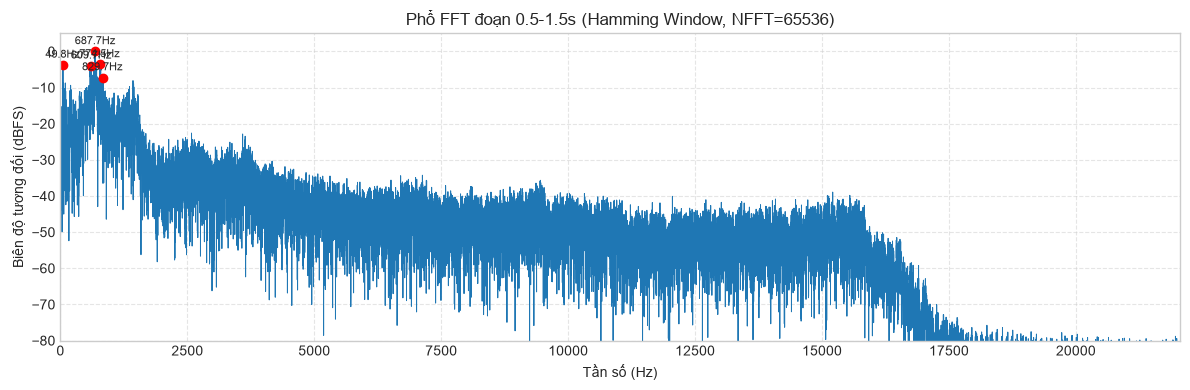

In [18]:
from scipy.signal import find_peaks

# 1. Trích xuất đoạn tín hiệu ổn định
seg = x[idx_start:idx_end]
N_seg = len(seg)

# 2. Nhân cửa sổ Hamming để giảm gợn phổ
window = np.hamming(N_seg)
seg_windowed = seg * window

# 3. Tính FFT với NFFT = 65536
NFFT = 65536
X = np.fft.rfft(seg_windowed, n=NFFT)
freqs = np.fft.rfftfreq(NFFT, d=1/Fs)

# Biên độ tương đối theo dB
mag_db = 20 * np.log10(np.maximum(np.abs(X), 1e-12))
mag_db -= np.max(mag_db)  # Chuẩn hóa max 0 dB

delta_f = Fs / NFFT
print(f"Frequency bin spacing (Δf): {delta_f:.3f} Hz")

# 4. Tìm các đỉnh phổ nổi bật
peaks, _ = find_peaks(mag_db, height=-30, distance=int(50/delta_f))
top_peaks = sorted(zip(freqs[peaks], mag_db[peaks]), key=lambda item: item[1], reverse=True)[:5]

print("\n--- CÁC ĐỈNH PHỔ NỔI BẬT (TOP PEAKS) ---")
for idx, (f_peak, p_val) in enumerate(top_peaks, 1):
    print(f"Peak {idx}: Tần số = {f_peak:.2f} Hz | Biên độ = {p_val:.2f} dB")

# 5. Vẽ phổ FFT
plt.figure(figsize=(12, 4))
plt.plot(freqs, mag_db, color='tab:blue', linewidth=0.7)
plt.xlim(0, Fs / 2)  # Hiển thị tới tần số Nyquist
plt.ylim(-80, 5)
plt.title(f"Phổ FFT đoạn {t_start}-{t_end}s (Hamming Window, NFFT={NFFT})")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ tương đối (dBFS)")
plt.grid(True, linestyle='--', alpha=0.5)

# Đánh dấu đỉnh
for f_peak, p_val in top_peaks:
    plt.plot(f_peak, p_val, 'ro')
    plt.annotate(f"{f_peak:.1f}Hz", (f_peak, p_val + 2), fontsize=8, ha='center')

plt.tight_layout()
plt.savefig("figures/fft.png", dpi=300)
plt.show()

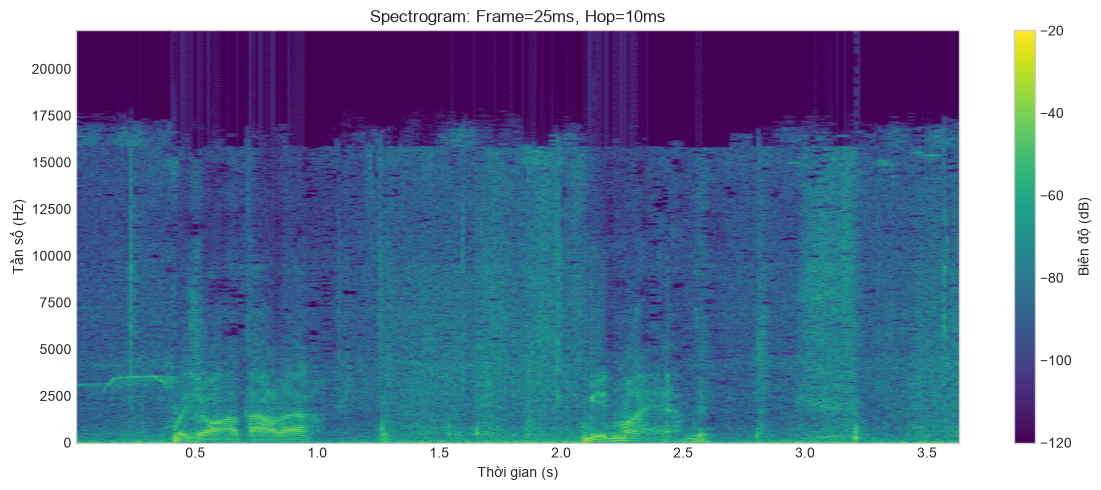

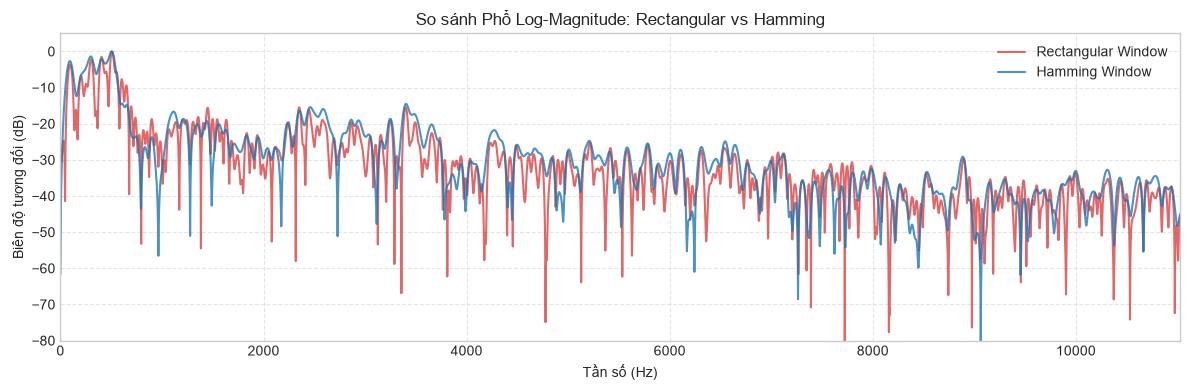

In [19]:
from scipy import signal

# 1. Biểu diễn Spectrogram (STFT)
win_length_sec = 0.025  # Frame ~ 25 ms
hop_length_sec = 0.010  # Hop ~ 10 ms

nperseg = round(win_length_sec * Fs)
noverlap = nperseg - round(hop_length_sec * Fs)

f_stft, t_stft, Sxx = signal.spectrogram(
    x,
    fs=Fs,
    window='hamming',
    nperseg=nperseg,
    noverlap=noverlap,
    nfft=2048,
    mode='magnitude'
)

S_db = 20 * np.log10(np.maximum(Sxx, 1e-12))

plt.figure(figsize=(12, 5))
pcol = plt.pcolormesh(t_stft, f_stft, S_db, shading='gouraud', cmap='viridis', vmin=-120, vmax=-20)
plt.colorbar(pcol, label="Biên độ (dB)")
plt.ylim(0, Fs / 2)
plt.title(f"Spectrogram: Frame={win_length_sec*1000:.0f}ms, Hop={hop_length_sec*1000:.0f}ms")
plt.xlabel("Thời gian (s)")
plt.ylabel("Tần số (Hz)")
plt.tight_layout()
plt.savefig("figures/spectrogram.png", dpi=300)
plt.show()

# 2. Thí nghiệm Cửa sổ: Rectangular vs Hamming
frame_sample = seg[:nperseg]
win_rect = np.ones(nperseg)
win_hamm = np.hamming(nperseg)

X_rect = np.fft.rfft(frame_sample * win_rect, n=NFFT)
X_hamm = np.fft.rfft(frame_sample * win_hamm, n=NFFT)

db_rect = 20 * np.log10(np.maximum(np.abs(X_rect), 1e-12))
db_hamm = 20 * np.log10(np.maximum(np.abs(X_hamm), 1e-12))

plt.figure(figsize=(12, 4))
plt.plot(freqs, db_rect - np.max(db_rect), label="Rectangular Window", alpha=0.7, color='tab:red')
plt.plot(freqs, db_hamm - np.max(db_hamm), label="Hamming Window", alpha=0.8, color='tab:blue')
plt.xlim(0, Fs / 4)
plt.ylim(-80, 5)
plt.title("So sánh Phổ Log-Magnitude: Rectangular vs Hamming")
plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ tương đối (dB)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("figures/window_experiment.png", dpi=300)
plt.show()

FIR LPF: Taps = 201, Cutoff = 2000.0 Hz
Group Delay: 100 mẫu (~2.27 ms)
Đã xuất file âm thanh sau lọc: audio/filtered_lpf_2kHz.wav


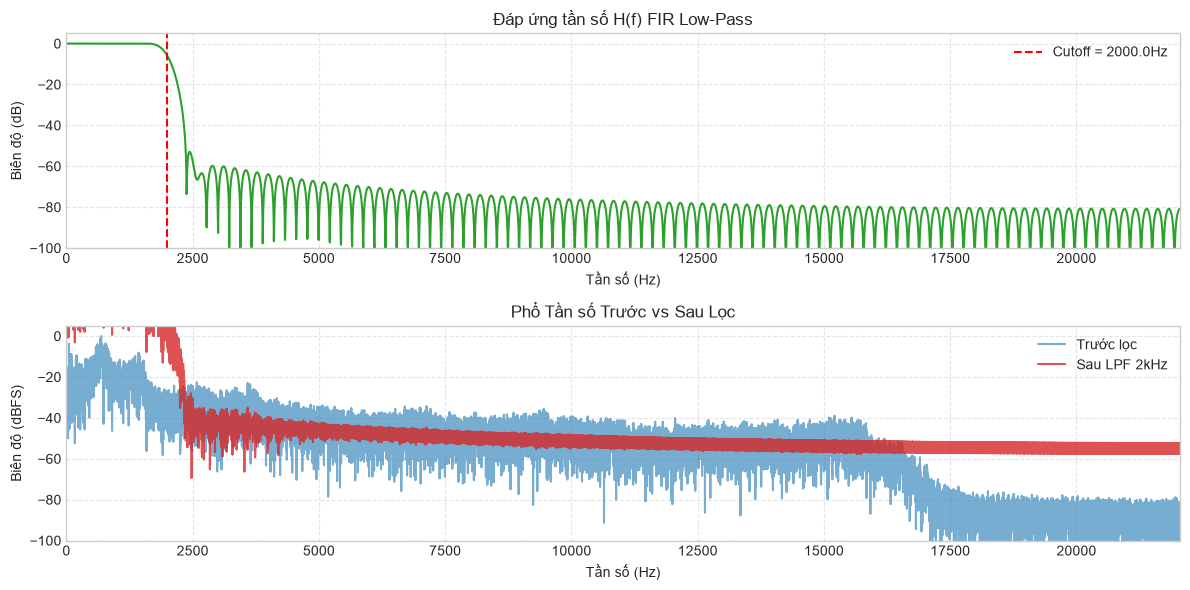

In [20]:
# 1. Thiết kế bộ lọc FIR Low-Pass (Cutoff = 2000 Hz)
numtaps = 201
cutoff_hz = 2000.0

b_lpf = signal.firwin(numtaps, cutoff=cutoff_hz, fs=Fs, window='hamming')

group_delay_samples = (numtaps - 1) // 2
group_delay_ms = (group_delay_samples / Fs) * 1000.0
print(f"FIR LPF: Taps = {numtaps}, Cutoff = {cutoff_hz} Hz")
print(f"Group Delay: {group_delay_samples} mẫu (~{group_delay_ms:.2f} ms)")

# 2. Áp dụng lọc
y_filtered = signal.lfilter(b_lpf, [1.0], x)

# 3. Xuất file WAV nghe thử
output_wav_path = "audio/filtered_lpf_2kHz.wav"
sf.write(output_wav_path, y_filtered, Fs)
print(f"Đã xuất file âm thanh sau lọc: {output_wav_path}")

# 4. Vẽ Đáp ứng tần số & Phổ trước/sau lọc
w_freq, H_resp = signal.freqz(b_lpf, [1.0], worN=4096, fs=Fs)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(w_freq, 20 * np.log10(np.maximum(np.abs(H_resp), 1e-12)), color='tab:green')
axes[0].axvline(cutoff_hz, color='red', linestyle='--', label=f'Cutoff = {cutoff_hz}Hz')
axes[0].set_title("Đáp ứng tần số H(f) FIR Low-Pass")
axes[0].set_xlabel("Tần số (Hz)")
axes[0].set_ylabel("Biên độ (dB)")
axes[0].set_xlim(0, Fs / 2)
axes[0].set_ylim(-100, 5)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

Y_filt = np.fft.rfft(y_filtered[idx_start:idx_end] * window, n=NFFT)
mag_db_filt = 20 * np.log10(np.maximum(np.abs(Y_filt), 1e-12))
mag_db_filt -= np.max(mag_db)

axes[1].plot(freqs, mag_db, label="Trước lọc", alpha=0.6, color='tab:blue')
axes[1].plot(freqs, mag_db_filt, label="Sau LPF 2kHz", alpha=0.8, color='tab:red')
axes[1].set_title("Phổ Tần số Trước vs Sau Lọc")
axes[1].set_xlabel("Tần số (Hz)")
axes[1].set_ylabel("Biên độ (dBFS)")
axes[1].set_xlim(0, Fs / 2)
axes[1].set_ylim(-100, 5)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/filter_response.png", dpi=300)
plt.show()

--- THỰC NGHIỆM LƯỢNG TỬ HÓA VÀ SNR ---
Bit Depth (B)   | SNR Đo Được (dB)     | Mô Tả Lý Thuyết (6B + 4.77 dB)
----------------------------------------------------------------------
4               | 8.12                 | ~28.77                         
6               | 20.22                | ~40.77                         
8               | 32.46                | ~52.77                         
12              | 56.61                | ~76.77                         
16              | 79.68                | ~100.77                        


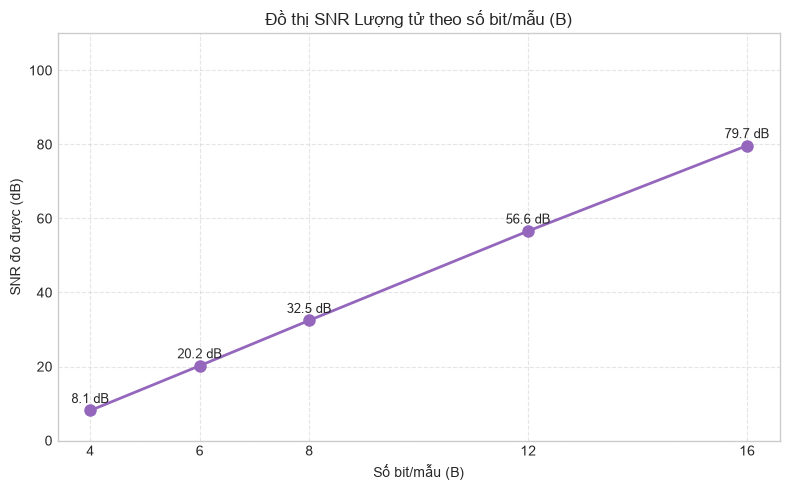

In [21]:
# 1. Hàm lượng tử hóa đều
def quantize_signal(x_in, B):
    qmax = 2 ** (B - 1) - 1
    x_clipped = np.clip(x_in, -1.0, 1.0)
    return np.round(x_clipped * qmax) / qmax

# 2. Hàm tính SNR
def compute_snr(x_orig, x_quant):
    noise = x_quant - x_orig
    p_sig = np.sum(x_orig ** 2)
    p_noise = np.sum(noise ** 2)
    if p_noise == 0:
        return float('inf')
    return 10 * np.log10(p_sig / p_noise)

# 3. Chạy các mức bit
bit_depths = [4, 6, 8, 12, 16]
snr_results = []

print("--- THỰC NGHIỆM LƯỢNG TỬ HÓA VÀ SNR ---")
print(f"{'Bit Depth (B)':<15} | {'SNR Đo Được (dB)':<20} | {'Mô Tả Lý Thuyết (6B + 4.77 dB)':<30}")
print("-" * 70)

for B in bit_depths:
    xq = quantize_signal(x, B)
    snr_val = compute_snr(x, xq)
    snr_results.append(snr_val)
    
    if B in [4, 8]:
        sf.write(f"audio/quantized_{B}bit.wav", xq, Fs)
        
    print(f"{B:<15} | {snr_val:<20.2f} | ~{6 * B + 4.77:<30.2f}")

# 4. Đồ thị SNR
plt.figure(figsize=(8, 5))
plt.plot(bit_depths, snr_results, 'o-', color='tab:purple', linewidth=2, markersize=8)
for b, snr_v in zip(bit_depths, snr_results):
    plt.annotate(f"{snr_v:.1f} dB", (b, snr_v + 2), ha='center', fontsize=9)

plt.title("Đồ thị SNR Lượng tử theo số bit/mẫu (B)")
plt.xlabel("Số bit/mẫu (B)")
plt.ylabel("SNR đo được (dB)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(bit_depths)
plt.ylim(0, 110)
plt.tight_layout()
plt.savefig("figures/quantization_snr.png", dpi=300)
plt.show()

In [23]:
!pip install --upgrade ipywidgets jupyter

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ------------------ --------------------- 1.0/2.2 MB 5.5 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 5.7 MB/s  0:00:00
   ---------------------------------------- 0.0/5.5 MB ? eta -:--:--
   ------- -------------------------------- 1.0/5.5 MB 6.0 MB/s eta 0:00:01
   ----------------- ---------------------- 2.4/5.5 MB 6.2 MB/s eta 0:00:01
   -------------------------- ------------- 3.7/5.5 MB 6.2 MB/s eta 0:00:01
   ---------------------------------- ----- 4.7/5.5 MB 6.1 MB/s eta 0:00:01
   ---------------------------------------- 5.5/5.5 MB 5.7 MB/s  0:00:00

   ------------- -------------------------- 2/6 [ipywidgets]
   ------------- -------------------------- 2/6 [ipywidgets]
   ------------- -------------------------- 2/6 [ipywidgets]
   ------------- -------------------------- 2/6 [ipywidgets]
   ------------- -------------------------- 2/6 [ipywidgets]
   -------------------- ------

In [24]:
import librosa

# 1. Resampling về 16 kHz và 8 kHz
for target_fs in [16000, 8000]:
    if Fs > target_fs:
        x_resampled = librosa.resample(x, orig_sr=Fs, target_sr=target_fs)
        sf.write(f"audio/resampled_{target_fs//1000}kHz.wav", x_resampled, target_fs)
        print(f"Đã resample về {target_fs} Hz -> audio/resampled_{target_fs//1000}kHz.wav")

# 2. Tính Bitrate PCM và Dung lượng File
bit_depth_val = 16  # Giả định chuẩn PCM 16-bit
R_pcm_bps = Fs * bit_depth_val * channels
R_pcm_kbps = R_pcm_bps / 1000.0

calc_size_mb = (R_pcm_bps * duration_sec / 8.0) / (1024 * 1024)
actual_size_mb = file_size_bytes / (1024 * 1024)

print("\n=" * 50)
print("--- PHÂN TÍCH TỐC ĐỘ BIT VÀ KÍCH THƯỚC FILE WAV ---")
print(f"Tốc độ Bit PCM (Bit Rate): {R_pcm_kbps:.1f} kbps")
print(f"Kích thước tính toán lý thuyết: {calc_size_mb:.2f} MB")
print(f"Kích thước thực tế trên đĩa: {actual_size_mb:.2f} MB")
print("=" * 50)

Đã resample về 16000 Hz -> audio/resampled_16kHz.wav
Đã resample về 8000 Hz -> audio/resampled_8kHz.wav

=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
--- PHÂN TÍCH TỐC ĐỘ BIT VÀ KÍCH THƯỚC FILE WAV ---
Tốc độ Bit PCM (Bit Rate): 1411.2 kbps
Kích thước tính toán lý thuyết: 0.61 MB
Kích thước thực tế trên đĩa: 0.61 MB
